# Problème de données : le cours d'AXA (CS.PA) avant 2008

## Marche que sur l'ancienne version de la donnée (ne pas relancer les celulles)

**Avant fin 2007, Yahoo Finance a enregistré les cours de clôture d'AXA arrondis à l'euro près** (18 €, 19 €, 20 €…). Le vrai cours bouge de quelques centimes chaque jour, mais la série téléchargée ne change que lorsqu'il franchit un euro rond.

Conséquence : chaque rendement journalier d'AXA vaut **soit 0 %, soit environ ±5 %** (1 € sur ~18 €). Ces rendements ne sont pas réels. Ils faussent les features d'AXA et les cibles Markowitz d'**environ un quart du train**.

**Proposition** : remplacer CS.PA par une autre action dont l'historique est propre, puis regénérer le dataset une seule fois (section 3).

À lancer depuis le dossier du projet (celui qui contient `data/`).

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA = Path("data")
PROC = DATA / "processed" / "N63_wmax1"
SUSPECT, PEER, MARKET = "CS.PA", "BNP.PA", "^FCHI"     # BNP : valeur financière comparable, série saine
C_SUSPECT, C_PEER, C_OTHER = "#eb6834", "#2a78d6", "#b9b8b2"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.titleweight": "bold"})

prices = pd.read_csv(DATA / "raw" / "prices.csv", index_col=0, parse_dates=True)
rets = prices.pct_change(fill_method=None)
TICKERS = [c for c in prices.columns if not c.startswith("^")]
pct = lambda x: f"{x:+.2%}" if pd.notna(x) else ""

## 1. Le problème, sur des exemples

### Exemple 1 : trois semaines de janvier 2005

Rendements journaliers d'AXA, de BNP et du CAC 40. Le marché bouge tous les jours ; AXA reste à 0 %, puis saute d'un coup de +5,6 % ou −5,3 %.

In [2]:
ex = rets.loc["2005-01-03":"2005-01-21", [SUSPECT, PEER, MARKET]]
ex.map(pct).rename(columns=lambda c: f"rendement {c}")

,rendement CS.PA,rendement BNP.PA,rendement ^FCHI
Date,,,
2005-01-03,+0.00%,+0.75%,+0.90%
2005-01-04,+0.00%,+0.74%,+0.20%
2005-01-05,+0.00%,-0.55%,-0.88%
2005-01-06,+0.00%,+1.49%,+0.71%
2005-01-07,+0.00%,+1.10%,+0.56%
2005-01-10,+5.56%,+0.18%,-0.00%
2005-01-11,+0.00%,-0.36%,-0.74%
2005-01-12,-5.26%,-1.45%,-0.85%
2005-01-13,+0.00%,+0.37%,+0.47%


### Exemple 2 : les niveaux de prix sont des euros ronds

Sur les 40 premiers jours de données, la série d'AXA ne prend que **deux valeurs**. Leur rapport vaut exactement 19/18 : ce sont 18 € et 19 €, multipliés par le même facteur d'ajustement des dividendes.

In [3]:
levels = np.sort(prices[SUSPECT].iloc[:40].unique())
print("Valeurs prises sur les 40 premiers jours :", np.round(levels, 4))
print(f"Rapport entre les deux niveaux : {levels[1] / levels[0]:.6f}")
print(f"19 / 18                        : {19 / 18:.6f}")

Valeurs prises sur les 40 premiers jours : [3.9167 4.1343]
Rapport entre les deux niveaux : 1.055555
19 / 18                        : 1.055556


**Vérification directe chez Yahoo** (déjà faite, avec `yf.download("CS.PA", auto_adjust=False)`) : la colonne *Close*, non ajustée des dividendes, vaut 17,279615 puis 18,239594 début janvier 2005. Divisées par 0,95998 (le facteur de l'augmentation de capital d'AXA en 2009, que Yahoo applique aussi à *Close*), elles donnent **18,00 € et 19,00 €** exactement.

Le code pour refaire la vérification (internet nécessaire) :

In [4]:
import yfinance as yf
raw = yf.download(SUSPECT, start="2005-01-01", end="2005-01-31", auto_adjust=False, progress=False)
close = raw["Close"].squeeze()
print(pd.DataFrame({"Close Yahoo": close, "÷ 0,95998": (close / 0.95998).round(2)}).head(10))

            Close Yahoo  ÷ 0,95998
Date                              
2005-01-03    17.279615       18.0
2005-01-04    17.279615       18.0
2005-01-05    17.279615       18.0
2005-01-06    17.279615       18.0
2005-01-07    17.279615       18.0
2005-01-10    18.239594       19.0
2005-01-11    18.239594       19.0
2005-01-12    17.279615       18.0
2005-01-13    17.279615       18.0
2005-01-14    17.279615       18.0


### Exemple 3 : sur l'ensemble de la période

Part des jours où le cours ne bouge pas du tout. Pour une grande capitalisation, c'est normalement ~1 %.

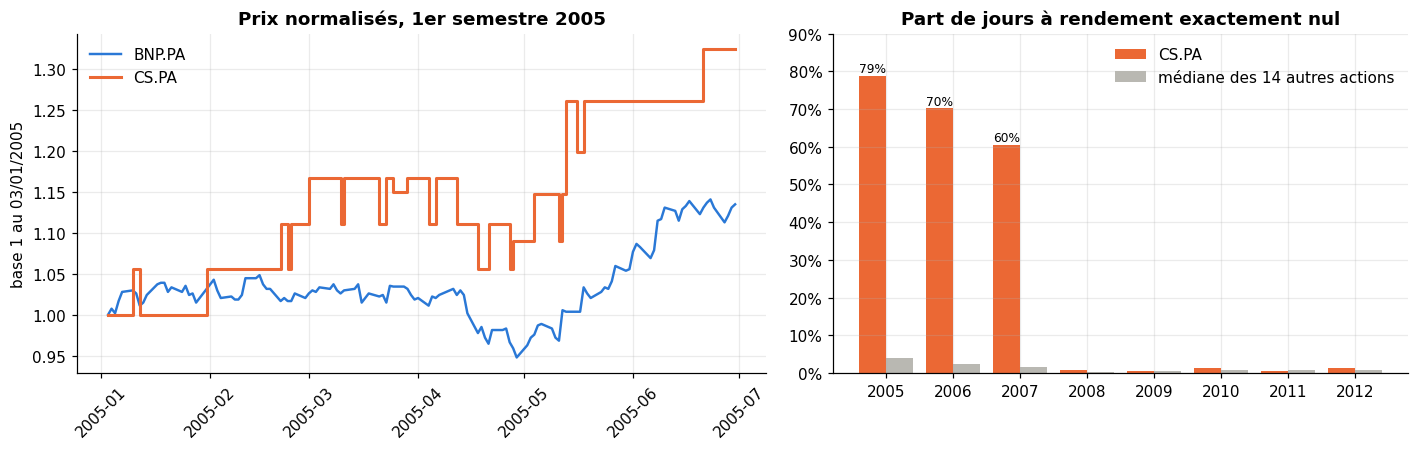

In [5]:
zero = (rets[TICKERS] == 0).groupby(rets.index.year).mean().loc[2005:2012]
others = zero.drop(columns=SUSPECT)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1.2, 1]})
ax = axes[0]
win = prices.loc["2005-01-01":"2005-06-30", [SUSPECT, PEER]]
norm = win / win.iloc[0]
ax.plot(norm.index, norm[PEER], color=C_PEER, lw=1.6, label=PEER)
ax.step(norm.index, norm[SUSPECT], where="post", color=C_SUSPECT, lw=2, label=SUSPECT)
ax.set_title("Prix normalisés, 1er semestre 2005"); ax.set_ylabel("base 1 au 03/01/2005")
ax.legend(frameon=False); ax.tick_params(axis="x", rotation=45)

ax = axes[1]
x = np.arange(len(zero.index))
ax.bar(x - 0.2, zero[SUSPECT], width=0.4, color=C_SUSPECT, label=SUSPECT)
ax.bar(x + 0.2, others.median(axis=1), width=0.4, color=C_OTHER, label="médiane des 14 autres actions")
for xi, v in zip(x, zero[SUSPECT]):
    if v > 0.05:
        ax.text(xi - 0.2, v + 0.01, f"{v:.0%}", ha="center", fontsize=8)
ax.set_xticks(x, zero.index); ax.set_ylim(0, 0.9)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_title("Part de jours à rendement exactement nul"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

Le défaut s'arrête fin 2007 : à partir de 2008, AXA redevient comparable aux autres actions. Il n'y a aucun petit mouvement sur 2005–2007, seulement des jours à 0 % et des sauts :

In [6]:
def profil(s):
    return pd.Series({"jours à 0 %": (s == 0).mean(),
                      "jours entre 0 et ±1 %": ((s != 0) & (s.abs() < 0.01)).mean(),
                      "jours au-delà de ±4 %": (s.abs() > 0.04).mean()})

pd.DataFrame({t: profil(rets.loc["2005":"2007", t]) for t in [SUSPECT, PEER, "TTE.PA", "SAN.PA"]}).map("{:.0%}".format)

,CS.PA,BNP.PA,TTE.PA,SAN.PA
jours à 0 %,70%,5%,2%,3%
jours entre 0 et ±1 %,0%,55%,63%,63%
jours au-delà de ±4 %,7%,2%,1%,1%


### Exemple 4 : un saut suspect le 12/05/2008

AXA prend +19,6 % alors que le CAC 40 et BNP sont stables. Ce n'est pas le même cas que le 19/09/2008 (interdiction des ventes à découvert), où tout le marché monte. Ça ressemble plutôt à un ajustement de dividende mal appliqué : c'est une raison de plus de ne pas garder cette série.

In [7]:
pd.concat([rets.loc["2008-05-08":"2008-05-14", [SUSPECT, PEER, MARKET]],
           rets.loc["2008-09-18":"2008-09-22", [SUSPECT, PEER, MARKET]]]).map(pct)

,CS.PA,BNP.PA,^FCHI
Date,,,
2008-05-08,-1.23%,-1.25%,-0.39%
2008-05-09,-1.87%,-2.10%,-1.88%
2008-05-12,+19.63%,-0.20%,+0.32%
2008-05-13,+0.80%,+0.29%,+0.45%
2008-05-14,+0.46%,+4.86%,+1.13%
2008-09-18,+2.52%,+2.99%,-1.06%
2008-09-19,+21.28%,+17.50%,+9.27%
2008-09-22,-5.38%,-2.94%,-2.34%


## 2. Impact sur le dataset actuel (`N63_wmax1`)

- **Features** : les fenêtres vont jusqu'à 252 jours. Une date est donc touchée jusqu'à environ un an après la fin du défaut (fin octobre 2007).
- **Cibles Y** : la cible de la date t utilise les rendements de t+1 à t+63. Elle est touchée si cette fenêtre recoupe la période défectueuse.
- La validation (2017–2019) et le test (2020–2025) ne sont pas touchés.

In [8]:
fin_defaut = pd.Timestamp("2007-10-30")                          # dernier plateau de prix figés
pos = rets.index.get_loc(fin_defaut)
fin_features = rets.index[pos + 252]

meta = pd.read_csv(PROC / "meta.csv", index_col=0, parse_dates=True)
impact = pd.DataFrame({
    "échantillons": meta["split"].value_counts(),
    "features touchées": meta.loc[meta.index < fin_features, "split"].value_counts(),
    "cibles touchées": meta.loc[meta.index < fin_defaut, "split"].value_counts(),
}).reindex(["train", "val", "test"]).fillna(0).astype(int)
impact["part des features touchées"] = (impact["features touchées"] / impact["échantillons"]).map("{:.0%}".format)
print(f"Features touchées jusqu'au {fin_features.date()}")
impact

Features touchées jusqu'au 2008-10-24


,échantillons,features touchées,cibles touchées,part des features touchées
split,,,,
train,2749,719,467,26%
val,703,0,0,0%
test,1474,0,0,0%


## 3. Proposition : remplacer CS.PA

**Option recommandée : changer d'action.** C'est un changement d'une ligne dans `build_dataset.py`. Le format de sortie ne change pas (15 actions + CASH, 160 features) ; seul le nom d'une colonne change.

Option alternative : garder AXA avec un historique propre d'une autre source (export CSV manuel depuis stooq.com, ticker `cs.fr`, ou Investing.com). C'est plus de travail, pour un gain limité.

### 3.1 Contrôle automatique d'une série de prix

Deux critères bloquants, plus une liste de sauts à vérifier à la main :
- moins de 15 % de jours à rendement nul chaque année ;
- au moins 100 valeurs de prix distinctes par année complète ;
- *à vérifier* : jours où l'action bouge de plus de 15 % alors que le CAC bouge de moins de 3 % (souvent un vrai événement, parfois une erreur).

Appliqué aux données actuelles, seul CS.PA échoue :

In [9]:
def controle_prix(px: pd.DataFrame, market: pd.Series) -> pd.DataFrame:
    r = px.pct_change(fill_method=None)
    m = market.pct_change(fill_method=None).reindex(r.index)
    full = px.loc[str(px.index.year.min() + 1):]                 # années complètes seulement
    rf = r.loc[full.index]
    res = pd.DataFrame({
        "max jours à 0 % (par an)": (rf == 0).groupby(rf.index.year).mean().max(),
        "min valeurs distinctes (par an)": full.groupby(full.index.year).nunique().min(),
    })
    res["verdict"] = np.where((res["max jours à 0 % (par an)"] < 0.15)
                              & (res["min valeurs distinctes (par an)"] >= 100), "OK", "ÉCHEC")
    sauts = r.where((r.abs() > 0.15) & (m.abs() < 0.03).to_numpy()[:, None])
    res["sauts isolés à vérifier"] = [", ".join(f"{d.date()} ({v:+.0%})" for d, v in sauts[t].dropna().items())
                                      for t in px.columns]
    res["max jours à 0 % (par an)"] = res["max jours à 0 % (par an)"].map("{:.0%}".format)
    return res

controle_prix(prices[TICKERS], prices[MARKET])

,max jours à 0 % (par an),min valeurs distinctes (par an),verdict,sauts isolés à vérifier
MC.PA,5%,180,OK,
OR.PA,6%,178,OK,
BN.PA,8%,156,OK,
TTE.PA,2%,183,OK,
VIE.PA,4%,203,OK,
SAN.PA,3%,188,OK,2023-10-27 (-19%)
BNP.PA,7%,130,OK,2008-12-17 (-17%)
CS.PA,79%,15,ÉCHEC,2008-05-12 (+20%)
AIR.PA,3%,219,OK,"2006-06-14 (-26%), 2020-03-26 (+20%)"
SU.PA,4%,191,OK,


Les autres sauts listés sont de vrais événements : AIR.PA le 14/06/2006 (retards de l'A380), SAN.PA le 27/10/2023 (révision des objectifs), etc. Seul le saut d'AXA du 12/05/2008 est isolé et inexpliqué.

### 3.2 Tester des remplaçants (internet nécessaire)

Pour rester dans le secteur financier, GLE.PA (Société Générale) et ACA.PA (Crédit Agricole) sont les candidats naturels. On peut en ajouter d'autres. On garde un candidat seulement si son verdict est « OK » et que ses éventuels sauts isolés correspondent à de vrais événements.

In [10]:
import yfinance as yf
candidats = ["GLE.PA", "ACA.PA", "RI.PA", "EN.PA", "ML.PA"]
start, end = "2004-12-01", "2025-12-31"                       # mêmes dates que build_dataset.py
px_c = yf.download(candidats + [MARKET], start=start, end=end, auto_adjust=True, progress=False)["Close"]
controle_prix(px_c[candidats], px_c[MARKET])

,max jours à 0 % (par an),min valeurs distinctes (par an),verdict,sauts isolés à vérifier
Ticker,,,,
GLE.PA,4%,189,OK,
ACA.PA,2%,208,OK,"2008-06-05 (-15%), 2008-10-21 (+16%)"
RI.PA,6%,182,OK,2007-01-16 (-16%)
EN.PA,3%,221,OK,2005-01-07 (+20%)
ML.PA,3%,195,OK,


### 3.3 Appliquer le changement

1. Dans `build_dataset.py`, remplacer le ticker dans `TICKERS` (exemple avec GLE.PA) :
   ```python
   "BNP.PA", "GLE.PA",                     # financials   (au lieu de "BNP.PA", "CS.PA")
   ```
2. Ajouter le contrôle dans `run_checks()`, pour qu'une série défectueuse fasse échouer la construction :
   ```python
   zero = (rets == 0).groupby(rets.index.year).mean()
   res["no_stale_prices"] = bool((zero < 0.15).all().all())
   ```
3. Supprimer `data/raw/prices.csv` (le fichier macro peut être gardé), puis relancer :
   ```
   python build_dataset.py
   python build_dataset.py --wmax 0.25
   ```
4. Relancer ce notebook avec `SUSPECT = "GLE.PA"` : la section 3.1 doit afficher « OK » partout.
5. Prévenir l'équipe : nouvelle version des données, à utiliser par tout le monde à partir de maintenant.